# Developing AI/ML: predicting outpatient no-shows, end to end

**What this notebook is.** One prediction problem everyone in the building understands,
walked from raw rows to a deployed-ish model in about 25 minutes. The data is synthetic and
generated in the first cell, so there is no PHI, no download, and nothing to break on a
managed laptop.

**What this notebook is not.** A tutorial on syntax. Narrate what each block does and why.

| Block | Minutes | What the room should take away |
|---|---|---|
| 1. Generate the data | 2 | The step that takes 20 seconds here and four months in real life |
| 2. Look at the data | 3 | The base rate. Plant the 82% number now |
| 3. Frame the prediction | 2 | Split by time, not at random |
| 4. Train a baseline | 3 | "Is 84% good?" |
| 5. Evaluate properly | 5 | The clinic picks the threshold, not the model |
| 6. Feature importance and the trap | 4 | Target leakage. The data engineer is worth more than the model |
| 7. Check for bias | 3 | The model learned the process, not the patient |
| 8. Ship it, sort of | 3 | Who is watching this number in month three? |

If you run long, cut block 7. Blocks 5, 6 and 8 are the talk.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
print("ready")

ready


## Block 1. Generate the data (2 min)

One function builds 20,000 synthetic outpatient appointments. The signal is realistic:
long lead times and a history of no-shows drive the outcome, reminders reduce it.

Two things are planted on purpose and revealed later:

- a column that is only populated **after** the appointment outcome is known
- a group of patients whose history the system records badly and whose no-shows are driven by
  things the data never captures

> **Talking point.** This is the one step that takes 20 seconds here and four months in real
> life: finding the tables, getting access, agreeing on what "no-show" even means, and
> learning how every column actually gets populated.

In [2]:
DEPARTMENTS = ["Primary Care", "Cardiology", "Dermatology", "Orthopedics", "Behavioral Health"]
DEPT_MIX = [0.40, 0.15, 0.15, 0.15, 0.15]
DEPT_EFFECT = {"Primary Care": 0.0, "Cardiology": -0.30, "Dermatology": 0.30,
               "Orthopedics": -0.10, "Behavioral Health": 0.50}
DISTANCE_BUCKETS = ["<5 mi", "5-15 mi", "15-30 mi", "30+ mi"]
DISTANCE_EFFECT = [0.0, 0.15, 0.35, 0.60]
BUSINESS_DAYS = pd.bdate_range("2024-01-01", "2025-12-31")


def make_appointments(n: int, rng: np.random.Generator, lead_time_mean: float = 21.0,
                      dates=BUSINESS_DAYS) -> pd.DataFrame:
    """Synthetic outpatient appointments with a no_show label."""
    appt_date = pd.DatetimeIndex(rng.choice(dates, n))
    lead_time = np.clip(rng.gamma(shape=2.0, scale=lead_time_mean / 2.0, size=n).round(), 0, 120)
    appt_hour = rng.choice(np.arange(8, 17), n, p=[0.14, 0.13, 0.13, 0.12, 0.06, 0.12, 0.12, 0.10, 0.08])
    department = rng.choice(DEPARTMENTS, n, p=DEPT_MIX)
    true_prior_no_shows = np.clip(rng.poisson(0.6, n), 0, 6)
    distance_idx = rng.choice(4, n, p=[0.35, 0.35, 0.20, 0.10])
    new_patient = rng.random(n) < 0.25
    portal_account = rng.random(n) < 0.65

    # The reminder process reaches portal users far more reliably than everyone else.
    reminder_sent = rng.random(n) < np.where(portal_account, 0.90, 0.45)

    # Patients outside the portal are scheduled by phone and paper. Their history is
    # under-recorded: each past no-show makes it into the system only 25% of the time.
    recorded_prior_no_shows = np.where(portal_account, true_prior_no_shows,
                                       rng.binomial(true_prior_no_shows, 0.25))

    observed_signal = (
        0.07 * lead_time
        + 1.10 * true_prior_no_shows
        + 0.45 * new_patient
        + np.vectorize(DEPT_EFFECT.get)(department)
        + np.take(DISTANCE_EFFECT, distance_idx)
        + 0.25 * (appt_date.dayofweek == 0)
        + 0.20 * (appt_hour == 8)
    )
    # For the non-portal group the recorded features explain less of what happens, and
    # unrecorded barriers (transport, shift work, caregiving) explain more. The model never
    # sees those barriers; the bias check in block 7 can still see their effect.
    signal_scale = np.where(portal_account, 1.0, 0.3)
    unobserved = rng.normal(0.0, 1.0, n) * np.where(portal_account, 0.3, 1.5) + np.where(portal_account, 0.0, 1.5)
    logit = -3.6 - 1.3 * reminder_sent + observed_signal * signal_scale + unobserved
    p_no_show = 1.0 / (1.0 + np.exp(-logit))
    no_show = rng.random(n) < p_no_show

    # THE TRAP. "Reminder confirmed" is written by the front desk when the patient checks in,
    # i.e. after we already know the outcome. It looks like a feature. It is the answer.
    reminder_confirmed = np.where(no_show, rng.random(n) < 0.03, rng.random(n) < 0.95)

    return pd.DataFrame({
        "appt_date": appt_date,
        "department": department,
        "appt_hour": appt_hour,
        "day_of_week": appt_date.dayofweek,          # 0 = Monday
        "lead_time_days": lead_time.astype(int),
        "prior_no_shows": recorded_prior_no_shows,
        "distance_bucket": np.take(DISTANCE_BUCKETS, distance_idx),
        "new_patient": new_patient.astype(int),
        "portal_account": portal_account.astype(int),
        "reminder_sent": reminder_sent.astype(int),
        "reminder_confirmed": reminder_confirmed.astype(int),
        "no_show": no_show.astype(int),
    }).sort_values("appt_date").reset_index(drop=True)


df = make_appointments(20_000, rng)
print(f"{len(df):,} appointments from {df.appt_date.min().date()} to {df.appt_date.max().date()}")

20,000 appointments from 2024-01-01 to 2025-12-31


## Block 2. Look at the data (3 min)

Before any modelling: what does a row look like, and how often does the thing we care about
actually happen?

> **Talking point.** The base rate is about 18%. So a "model" that says *everyone shows up*
> is about 82% accurate. Remember that number. We will come back to it.

In [3]:
df.sample(8, random_state=RANDOM_SEED).sort_values("appt_date")

,appt_date,department,appt_hour,day_of_week,lead_time_days,prior_no_shows,distance_bucket,new_patient,portal_account,reminder_sent,reminder_confirmed,no_show
1114,2024-02-08,Orthopedics,14,3,36,1,15-30 mi,0,1,1,0,1
2041,2024-03-14,Behavioral Health,10,3,41,0,5-15 mi,0,1,1,0,1
3002,2024-04-17,Cardiology,10,2,29,0,<5 mi,1,0,0,1,0
8668,2024-11-08,Primary Care,11,4,20,0,<5 mi,0,0,0,1,0
10650,2025-01-20,Dermatology,14,0,9,0,5-15 mi,0,1,1,1,0
11072,2025-02-04,Dermatology,13,1,18,0,<5 mi,1,0,1,1,0
11963,2025-03-07,Primary Care,10,4,28,1,<5 mi,0,1,1,1,0
13902,2025-05-20,Cardiology,11,1,14,1,15-30 mi,0,1,1,1,0


In [4]:
base_rate = df.no_show.mean()
print(f"Overall no-show rate: {base_rate:.1%}")
print(f"'Everyone shows up' accuracy: {1 - base_rate:.1%}\n")
print("No-show rate by department")
print(df.groupby("department").no_show.mean().sort_values(ascending=False).map("{:.1%}".format))

Overall no-show rate: 18.3%
'Everyone shows up' accuracy: 81.7%

No-show rate by department
department
Behavioral Health    22.3%
Dermatology          21.2%
Primary Care         17.7%
Orthopedics          16.2%
Cardiology           15.0%
Name: no_show, dtype: str


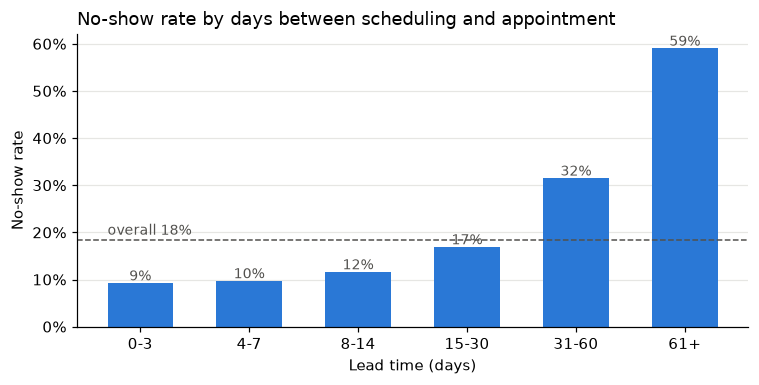

In [5]:
lead_bins = [-1, 3, 7, 14, 30, 60, 120]
lead_labels = ["0-3", "4-7", "8-14", "15-30", "31-60", "61+"]
df["lead_bucket"] = pd.cut(df.lead_time_days, bins=lead_bins, labels=lead_labels)
by_lead = df.groupby("lead_bucket", observed=True).no_show.mean()

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(by_lead.index.astype(str), by_lead.values, color=BLUE, width=0.6)
ax.axhline(base_rate, color=GRAY, lw=1, ls="--")
ax.text(-0.3, base_rate + 0.012, f"overall {base_rate:.0%}", ha="left", color=GRAY, fontsize=9)
ax.set_title("No-show rate by days between scheduling and appointment", loc="left")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("No-show rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for b, v in zip(bars, by_lead.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.0%}", ha="center", fontsize=9, color=GRAY)
plt.tight_layout()
plt.show()

## Block 3. Frame the prediction (2 min)

- **Predicting what?** Whether a scheduled appointment will be a no-show.
- **For whom?** The scheduling team, the day before.
- **What happens with the answer?** Something cheap (a reminder call) or something expensive
  (overbooking the slot). Hold that thought for block 5.

The split is **by time**: train on older appointments, test on newer ones.

> **Talking point.** A random shuffle leaks the future into the past. Appointments from the
> same patient, the same week, the same scheduling template land on both sides of the split
> and the score looks better than it ever will in production. Most tutorial models cheat
> here without meaning to.

In [6]:
FEATURES = ["department", "appt_hour", "day_of_week", "lead_time_days", "prior_no_shows",
            "distance_bucket", "new_patient", "portal_account", "reminder_sent"]
CATEGORICAL = ["department", "distance_bucket"]
TARGET = "no_show"
CUTOFF = pd.Timestamp("2025-07-01")

train = df[df.appt_date < CUTOFF]
test = df[df.appt_date >= CUTOFF]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"train: {len(train):,} appointments before {CUTOFF.date()}  (no-show {y_train.mean():.1%})")
print(f"test:  {len(test):,} appointments from   {CUTOFF.date()}  (no-show {y_test.mean():.1%})")


def make_pipeline(model, categorical=CATEGORICAL):
    prep = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), categorical)],
        remainder="passthrough",
    )
    return Pipeline([("prep", prep), ("model", model)])

train: 15,070 appointments before 2025-07-01  (no-show 18.3%)
test:  4,930 appointments from   2025-07-01  (no-show 18.2%)


## Block 4. Train a baseline (3 min)

Two models, both train in seconds: a logistic regression and a gradient-boosted tree.

> **Talking point.** Pause after the numbers print. *"Is that good?"* Let the room sit with
> it. Then point back at the 82% from block 2.

In [7]:
logreg = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
gbt = make_pipeline(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                   random_state=RANDOM_SEED)).fit(X_train, y_train)

for name, m in [("Logistic regression", logreg), ("Gradient boosted trees", gbt)]:
    print(f"{name:24s} accuracy on new appointments: {accuracy_score(y_test, m.predict(X_test)):.1%}")

print(f"{'Everyone shows up':24s} accuracy on new appointments: {1 - y_test.mean():.1%}")

Logistic regression      accuracy on new appointments: 82.6%
Gradient boosted trees   accuracy on new appointments: 83.3%
Everyone shows up        accuracy on new appointments: 81.8%


## Block 5. Evaluate properly (5 min)

Accuracy hides the thing we care about. Look at the two kinds of mistakes separately.

- **Precision**: of the appointments we flag, how many really no-show?
- **Recall**: of the real no-shows, how many did we flag?

              precision    recall  f1-score   support

      showed      0.845     0.975     0.905      4033
     no-show      0.638     0.196     0.300       897

    accuracy                          0.833      4930
   macro avg      0.741     0.586     0.603      4930
weighted avg      0.807     0.833     0.795      4930

ROC AUC: 0.761


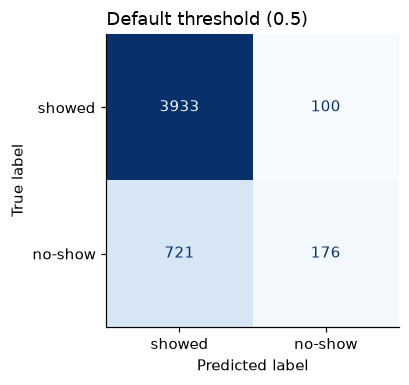

In [8]:
model = gbt
proba_test = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, model.predict(X_test), target_names=["showed", "no-show"], digits=3))
print(f"ROC AUC: {roc_auc_score(y_test, proba_test):.3f}")

fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["showed", "no-show"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Default threshold (0.5)", loc="left")
plt.tight_layout()
plt.show()

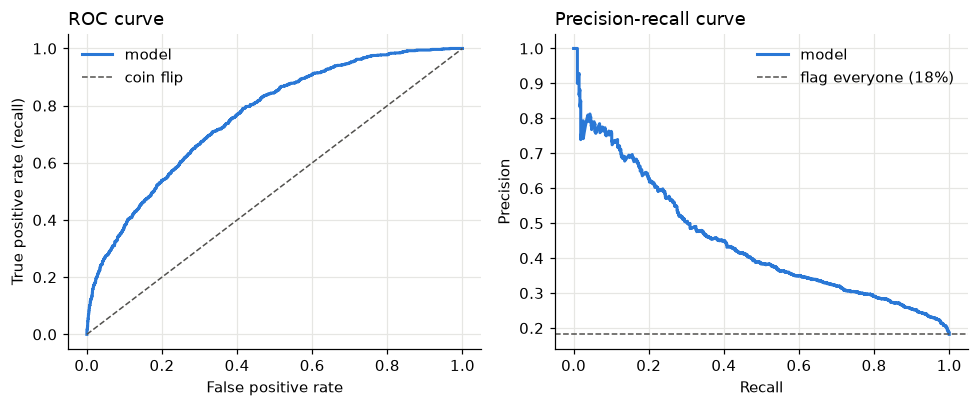

In [9]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
a1.plot(fpr, tpr, color=BLUE, lw=2, label="model")
a1.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="coin flip")
a1.set(xlabel="False positive rate", ylabel="True positive rate (recall)")
a1.set_title("ROC curve", loc="left")
a1.legend(frameon=False)

a2.plot(rec, prec, color=BLUE, lw=2, label="model")
a2.axhline(y_test.mean(), color=GRAY, lw=1, ls="--", label=f"flag everyone ({y_test.mean():.0%})")
a2.set(xlabel="Recall", ylabel="Precision")
a2.set_title("Precision-recall curve", loc="left")
a2.legend(frameon=False)
for a in (a1, a2):
    a.grid(color="#e6e6e3", lw=0.8)
    a.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Live change: move the threshold

The model outputs a probability. Somebody has to decide where to draw the line.

> **Talking point.** The model does not decide the threshold. The clinic does. If the
> intervention is a friendly reminder call, you tolerate false positives and go low. If the
> intervention is overbooking the slot, a false positive means two patients in one chair,
> and you go high.

In [10]:
def evaluate_at(threshold: float, proba=proba_test, y=y_test) -> dict:
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "flagged": int(pred.sum()),
        "flagged_share": pred.mean(),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "accuracy": accuracy_score(y, pred),
    }


sweep = pd.DataFrame([evaluate_at(t) for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60]])
sweep.style.format({"flagged_share": "{:.0%}", "precision": "{:.0%}", "recall": "{:.0%}", "accuracy": "{:.0%}"}) \
     .background_gradient(subset=["recall"], cmap="Blues")

,threshold,flagged,flagged_share,precision,recall,accuracy
0,0.100000,2889,59%,27%,87%,55%
1,0.150000,2160,44%,31%,74%,65%
2,0.200000,1676,34%,34%,63%,71%
3,0.250000,1266,26%,38%,53%,75%
4,0.300000,856,17%,43%,41%,79%
5,0.400000,448,9%,55%,27%,83%
6,0.500000,276,6%,64%,20%,83%
7,0.600000,155,3%,71%,12%,83%


In [11]:
# ---- change this number live and re-run the cell ----
THRESHOLD = 0.30

r = evaluate_at(THRESHOLD)
print(f"At threshold {THRESHOLD:.2f} we flag {r['flagged']:,} of {len(y_test):,} appointments ({r['flagged_share']:.0%}).")
print(f"  {r['precision']:.0%} of flagged appointments are real no-shows (precision)")
print(f"  {r['recall']:.0%} of real no-shows were caught (recall)")
print(f"  accuracy {r['accuracy']:.1%}")

At threshold 0.30 we flag 856 of 4,930 appointments (17%).
  43% of flagged appointments are real no-shows (precision)
  41% of real no-shows were caught (recall)
  accuracy 79.5%


## Block 6. Feature importance, and the planted trap (4 min)

What is the model actually using? Permutation importance: shuffle one column, see how much
the score drops.

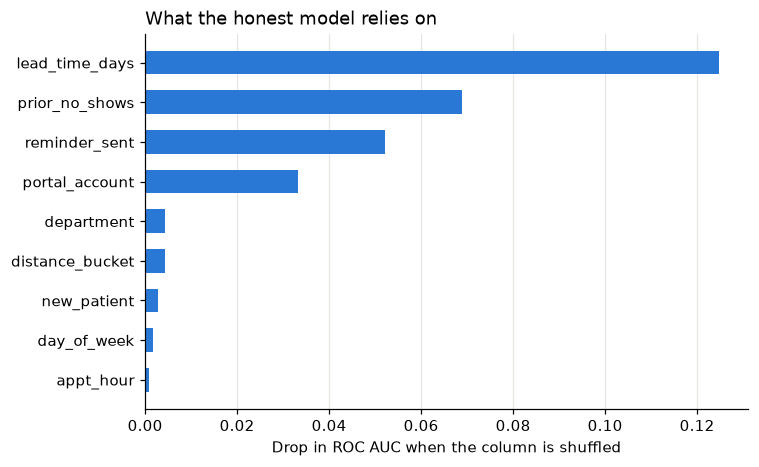

In [12]:
def show_importance(model, X, y, title, n_repeats=5):
    imp = permutation_importance(model, X, y, scoring="roc_auc", n_repeats=n_repeats,
                                 random_state=RANDOM_SEED, n_jobs=1)
    s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(s) + 1.2))
    ax.barh(s.index, s.values, color=[ORANGE if c == "reminder_confirmed" else BLUE for c in s.index], height=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Drop in ROC AUC when the column is shuffled")
    ax.grid(axis="x", color="#e6e6e3", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
    return s


_ = show_importance(gbt, X_test, y_test, "What the honest model relies on")

### The trap

Somebody from the front-desk system says: *"You skipped a column. `reminder_confirmed` is
right there in the table."* Add it, retrain.

accuracy without reminder_confirmed: 83.3%
accuracy with    reminder_confirmed: 95.9%   <-- too good to be true


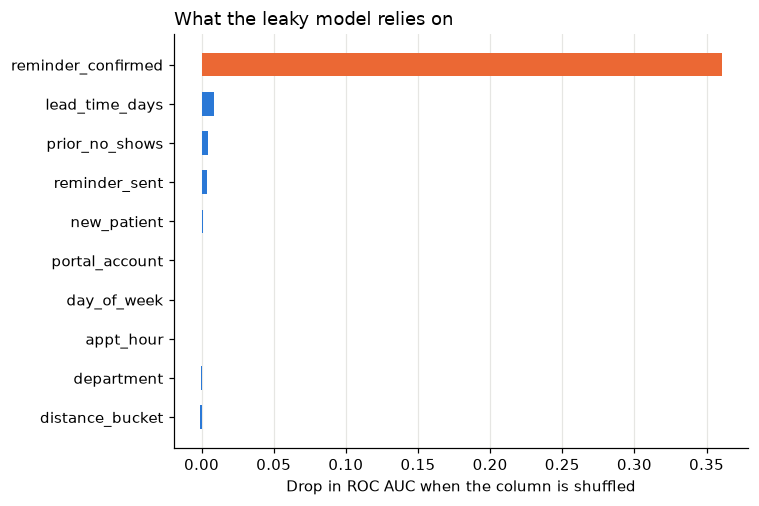

In [13]:
FEATURES_PLUS = FEATURES + ["reminder_confirmed"]
gbt_leaky = make_pipeline(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                         random_state=RANDOM_SEED)) \
    .fit(train[FEATURES_PLUS], y_train)

acc_honest = accuracy_score(y_test, gbt.predict(X_test))
acc_leaky = accuracy_score(y_test, gbt_leaky.predict(test[FEATURES_PLUS]))
print(f"accuracy without reminder_confirmed: {acc_honest:.1%}")
print(f"accuracy with    reminder_confirmed: {acc_leaky:.1%}   <-- too good to be true")

_ = show_importance(gbt_leaky, test[FEATURES_PLUS], y_test, "What the leaky model relies on")

> **Talking point.** That column is written when the patient checks in. It is populated
> *after* the outcome we are predicting. In the warehouse it looks like any other field. The
> model found the answer key and we would have shipped a system that cannot predict anything
> the day before.
>
> This is called **target leakage**, and no amount of modelling skill catches it. The data
> engineer who knows how that field gets populated is worth more than the model. We remove
> it and go back to the honest number.

## Block 7. Check for bias (3 min)

Does the model work equally well for everyone? Break recall out by whether the patient has a
patient-portal account, which in real systems tracks age, language and income.

In [14]:
def recall_by_group(model, X, y, group: pd.Series, threshold: float = THRESHOLD) -> pd.DataFrame:
    pred = (model.predict_proba(X)[:, 1] >= threshold).astype(int)
    out = pd.DataFrame({"group": group.values, "y": y.values, "pred": pred})
    g = out.groupby("group")
    return pd.DataFrame({
        "appointments": g.size(),
        "actual no-show rate": g.y.mean(),
        "recall (caught)": g.apply(lambda d: recall_score(d.y, d.pred)),
        "precision": g.apply(lambda d: precision_score(d.y, d.pred, zero_division=0)),
    })


fairness = recall_by_group(gbt, X_test, y_test, test.portal_account.map({1: "has portal account", 0: "no portal account"}))
fairness.style.format({"actual no-show rate": "{:.0%}", "recall (caught)": "{:.0%}", "precision": "{:.0%}"})

,appointments,actual no-show rate,recall (caught),precision
group,,,,
has portal account,3187,17%,52%,51%
no portal account,1743,21%,27%,31%


> **Talking point.** The group with the higher no-show rate is the group the model catches
> least. Not because they are harder to predict in principle, but because the historical
> reminder process reached them less, and the reasons they miss appointments were never
> recorded. **The model learned the process, not the patient.** Deploy this as-is and the
> reminder calls go to the people who were already getting reminders.

## Block 8. Ship it, sort of (3 min)

Save the model, wrap it in a function that takes one appointment and returns a probability.
This is the shape of every scoring endpoint you will ever see.

In [15]:
import joblib
from pathlib import Path

MODEL_PATH = Path("../models/no_show_gbt.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump({"pipeline": gbt, "features": FEATURES, "threshold": THRESHOLD, "trained_through": CUTOFF}, MODEL_PATH)
bundle = joblib.load(MODEL_PATH)


def predict_one(appointment: dict) -> dict:
    row = pd.DataFrame([appointment])[bundle["features"]]
    p = float(bundle["pipeline"].predict_proba(row)[0, 1])
    return {"no_show_probability": round(p, 3), "flag": p >= bundle["threshold"]}


print(predict_one({"department": "Cardiology", "appt_hour": 10, "day_of_week": 2, "lead_time_days": 5,
                   "prior_no_shows": 0, "distance_bucket": "<5 mi", "new_patient": 0,
                   "portal_account": 1, "reminder_sent": 1}))
print(predict_one({"department": "Behavioral Health", "appt_hour": 8, "day_of_week": 0, "lead_time_days": 45,
                   "prior_no_shows": 2, "distance_bucket": "30+ mi", "new_patient": 1,
                   "portal_account": 0, "reminder_sent": 0}))

{'no_show_probability': 0.019, 'flag': False}
{'no_show_probability': 0.422, 'flag': True}


### Live change: three months later

The clinic opened scheduling further out. Lead times stretched. Nobody told the model.

In [16]:
# ---- change lead_time_mean live: 21 was the training world ----
future = make_appointments(3_000, np.random.default_rng(7), lead_time_mean=45)

compare = pd.DataFrame({
    "test period (what we validated on)": {
        "mean lead time (days)": test.lead_time_days.mean(),
        "mean predicted no-show prob": proba_test.mean(),
        "share flagged": (proba_test >= THRESHOLD).mean(),
        "actual no-show rate": y_test.mean(),
    },
    "month three (what is arriving now)": {
        "mean lead time (days)": future.lead_time_days.mean(),
        "mean predicted no-show prob": gbt.predict_proba(future[FEATURES])[:, 1].mean(),
        "share flagged": (gbt.predict_proba(future[FEATURES])[:, 1] >= THRESHOLD).mean(),
        "actual no-show rate": future.no_show.mean(),
    },
})
compare.round(3)

,test period (what we validated on),month three (what is arriving now)
mean lead time (days),21.302,43.632
mean predicted no-show prob,0.182,0.345
share flagged,0.174,0.450
actual no-show rate,0.182,0.345


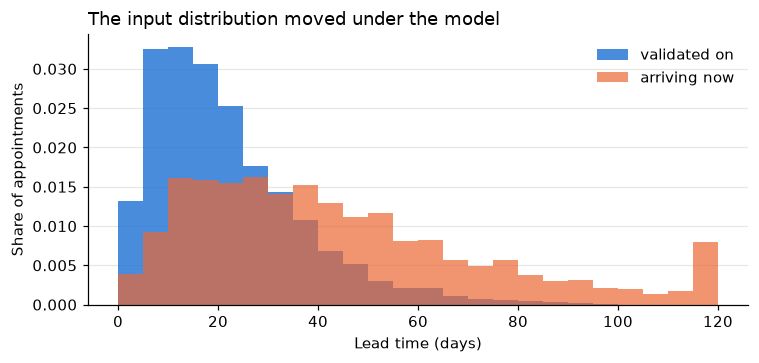

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(0, 125, 5)
ax.hist(test.lead_time_days, bins=bins, density=True, color=BLUE, alpha=0.85, label="validated on")
ax.hist(future.lead_time_days, bins=bins, density=True, color=ORANGE, alpha=0.7, label="arriving now")
ax.set_title("The input distribution moved under the model", loc="left")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Share of appointments")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

> **Talking point.** The share of appointments flagged just jumped. Nothing is broken, no
> alert fired, the endpoint returns 200. This is month three in production. **Who is watching
> this number?**
>
> That question is the handoff: everything after this slide is why the 25 minutes you just
> watched takes six months to ship for real.

---

## What this took vs. what it takes

| Here | In a health system |
|---|---|
| Data appeared in one cell | Data access, ownership, definitions, de-identification |
| 84% accuracy | A bar that means something clinically, agreed with the people who act on it |
| We found the leak because we planted it | Someone has to know how every column is populated |
| We checked one group | Fairness review, plus the question of what you do about it |
| The threshold was a variable | A decision owned by the clinic, documented, revisited |
| We noticed drift because we caused it | Monitoring, retraining triggers, someone on call |
| `predict_one` | Intake, risk review, PHI handling, logging, an owner |